# Case study: One-Tap Apply on LinkedIn Jobs

*A take-home style A/B test case. The company context is modeled on how LinkedIn describes its experimentation work publicly. The data is synthetic.*

## The brief

You're the product data scientist on the Jobs team. For 21 days (Oct 5 to Oct 25, 2026), the team ran an experiment on **One-Tap Apply**: members with a saved resume can apply to Easy Apply jobs in one tap, **skipping the optional screening questions** recruiters add to postings.

The PM posts in Slack on Monday morning:

> "Applications are up ~12%!! 🚀 Can we ship to 100% this week?"

**Your job:** decide whether to recommend launch, and back it up.

## Why this is a realistic interview case

Jobs is a **two-sided marketplace**. Job seekers want more applications to go out, and recruiters want good applicants they'll actually respond to. A change that helps one side can hurt the other. The classic trade-off is **volume vs. quality**: making applying easier raises application counts but can lower the quality recruiters see.

## Data (in `data/`)

| File | Grain | Columns |
|---|---|---|
| `assignments.csv` | 1 row per member exposed to the test | `member_id`, `variant`, `platform` (web / ios / android), `seeker_type` (active / passive), `tenure` (new / tenured), `first_exposure_date` |
| `daily_activity.csv` | 1 row per member per day **with at least one apply start** | `member_id`, `date`, `apply_starts`, `apply_submits` |
| `applications.csv` | 1 row per submitted application | `application_id`, `member_id`, `applied_date`, `recruiter_responded_7d` (1 if the recruiter viewed and replied within 7 days) |
| `pre_period.csv` | 1 row per member, 28 days **before** the test | `member_id`, `apply_submits_pre28` |

The test was designed as a **50/50 split, randomized by member**.

## How to work through it

- **Part A** is design: answer it in writing **before** you touch the data, the same way you would in an interview.
- **Parts B to F** are analysis. Fill in the `# TODO` cells. **Checkpoints** tell you roughly what you should see.
- **Part G** is the deliverable: a short launch memo.
- The solutions notebook has full answers. Try each part before you look.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
DATA = "data/"
ALPHA = 0.05

---
# Part A: Design the test (before looking at results)

Interviewers almost always start here. Answer in 2 to 4 sentences each.
____
**A1.** What's the hypothesis? Be specific about the mechanism.

By design, the one-click apply would be removing friction from the application process for each user. Thus, we would expect there to be a larger average number of applications that are submitted per user in the treatment group versus the control group. However, as a guard rail metric - it will be important to expect that the number for recruiter response rate would go down. We will want to consider if the net effect on recruiter responses per member is positive. 

Formal Set up: 

Two-Sided Set up 
H_0: Mean(Applications per User)_Control = Mean(Application per User)_Treatment 
H_A: Mean(Applications per User)_Control <> Mean(Application per User)_Treatment

One-Sided Set up 

H_0: Mean(Applications per User)_Control <= Mean(Applications per User)_Treatment 
H_A: Mean(Applications per User)_Control < Mean(Applications per User)_Treatment
_____
**A2.** Pick a **primary metric**, 1 to 2 **secondary metrics**, and at least 2 **guardrail metrics**. Define each one precisely: what's the numerator, the denominator, and the unit?
- **Primary:** apply submits per member over the test window (sum of submits / members exposed). Member-level, so it matches the randomization unit.
- **Secondary:** apply completion rate (submits / starts); share of members with at least 1 submit.
- **Guardrails:**
  - **Recruiter response rate** = applications with a 7-day recruiter response / applications. This is the employer side of the marketplace.
  - **Recruiter responses per member** = the outcome job seekers actually care about (a "match"). If this falls, the feature is hurting seekers too, even though applications went up.
  - Also standard: app crashes and latency, unsubscribes, job-seeker retention.
_____
**A3.** What is the randomization unit, and why? What could go wrong with member-level randomization in a jobs marketplace?

Randomization user will be the *members*. The risk here is that there could be an effect of the treatment group that may impact the control group. For example, if a recruiter posts a job listing - they may notice a influx of applications from the treatment group which could have an effect on the control group. 

**A4.** (code below) How many members per arm do you need to detect a **5% relative lift** in applications per member with 80% power at α = 0.05?

**Your answer:**

_Write it here before looking at the answer key._

**A4. Sample size.** Use the pre-period as a stand-in for the baseline (it covers 28 days, so scale it to 21 days first).

For a difference in means: n per arm = 2 (z₁₋α/₂ + z₁₋β)² σ² / δ², where δ is the absolute difference you want to detect.

In [14]:
pre = pd.read_csv(DATA + "pre_period.csv")
baseline = pre["apply_submits_pre28"] * 21 / 28

# TODO: mu and sigma of baseline

mu = sum(baseline) / len(baseline) 

squared_devs = (baseline - mu) ** 2
numerator = sum(squared_devs)
variance = numerator / (len(baseline) - 1)
sigma = np.sqrt(variance)

print(f"Mu: {mu} --- Sigma: {sigma}") 

# TODO: delta = 5% of mu
delta = mu * (0.05) # Problem Definition of 5% Effect Size 

# TODO: n_per_arm from the formula (use stats.norm.ppf for the z-values)
alpha = 0.05
beta = 0.2
z_alpha = stats.norm.ppf(1-alpha/2) # two-sided and to the right is what we are interested in. 
z_beta = stats.norm.ppf(1 - beta)
n_per_arm = 2 * (z_alpha + z_beta) ** 2 * sigma**2 / delta**2

print(f"Baseline Mean = {mu:.3f}, sd = {sigma:.3f}, coefficient of variation = {sigma / mu:.2f}")
print(f"n per arm for a 5% MDE: {n_per_arm:,.0f}")


Mu: 1.2746430274922111 --- Sigma: 3.7009658853464145
Baseline Mean = 1.275, sd = 3.701, coefficient of variation = 2.90
n per arm for a 5% MDE: 52,936


**Checkpoint:** the SD is almost 3x the mean (very skewed: most members apply 0 times, a few apply a lot). n per arm should come out around **53,000**, right at the edge of the ~50,000 per arm the test was planned with.

**Question:** what does that mean for this test? (Hint: Part C has a fix.)

---
# Part B: Can we trust the data?

Always do this before you read any results. A broken experiment produces confident but wrong numbers.

## B1. Build a member-level table

One row per member in `assignments.csv`, with these columns:
- `apply_starts`, `apply_submits`: sums from `daily_activity.csv` (members with no rows applied 0 times, so **fill with 0, don't drop them**)
- `responses`: sum of `recruiter_responded_7d` from `applications.csv` (fill 0)
- `apply_submits_pre28` from `pre_period.csv`

In [26]:
assign = pd.read_csv(DATA + "assignments.csv")
daily = pd.read_csv(DATA + "daily_activity.csv", parse_dates=["date"])
apps = pd.read_csv(DATA + "applications.csv", parse_dates=["applied_date"])

assign.head()

# TODO: aggregate daily to member level, aggregate apps to member level

activity = daily.groupby("member_id")[["apply_starts", "apply_submits"]].sum()
responses = apps.groupby("member_id")["recruiter_responded_7d"].sum().rename("responses")

# TODO: left-join onto assign, fill missing activity with 0, join pre-period

members = (
    assign
    .merge(activity, on = "member_id", how = "left")
    .merge(responses, on = "member_id", how = "left")
    .merge(pre, on = "member_id", how = "left")
    .fillna({"apply_starts": 0, "apply_submits" : 0, "responses" : 0})
)

print(members.shape) 
members.head()

(98537, 10)


,member_id,variant,platform,seeker_type,tenure,first_exposure_date,apply_starts,apply_submits,responses,apply_submits_pre28
0,32046993,treatment,web,passive,new,2026-10-06,0.0000,0.0000,0.0000,0
1,42447485,treatment,android,active,tenured,2026-10-05,16.0000,11.0000,5.0000,11
2,98028970,treatment,ios,passive,tenured,2026-10-06,2.0000,2.0000,0.0000,2
3,62058940,control,android,active,new,2026-10-07,3.0000,2.0000,0.0000,2
4,96257258,control,android,passive,tenured,2026-10-07,1.0000,1.0000,0.0000,0


## B2. Sample ratio mismatch (SRM)

The design was 50/50. Test whether the observed counts are consistent with that using a chi-square goodness-of-fit test (`stats.chisquare`). Then repeat it **for each platform**.

**Why it matters:** if the split is off, something is dropping users from one arm in a way that's probably **not random**, so the arms are no longer comparable.

In [43]:
def srm_test(counts):
    expected = np.full(len(counts), counts.sum()/len(counts))
    return stats.chisquare(counts.values, expected).pvalue

overall = members["variant"].value_counts() 

print(overall.to_dict(), f"ratio = {overall['treatment'] / overall.sum():.4f}, SRM p = {srm_test(overall):.2e}\n")

for plat, group in members.groupby("platform"): 
    c = group["variant"].value_counts() 
    print(f"{plat} {c.to_dict()} treatment share = {c["treatment"]/c.sum():.4f} SRM p = {srm_test(c):.2e}")


{'control': 50107, 'treatment': 48430} ratio = 0.4915, SRM p = 9.17e-08

android {'control': 14945, 'treatment': 13331} treatment share = 0.4715 SRM p = 8.13e-22
ios {'control': 14990, 'treatment': 14973} treatment share = 0.4997 SRM p = 9.22e-01
web {'control': 20172, 'treatment': 20126} treatment share = 0.4994 SRM p = 8.19e-01


**Checkpoint:** overall p should be tiny (< 1e-6). Only one platform should show a problem.

**B3. Questions:**
1. Which platform is broken, and what's a plausible cause?

*android* is the problem. There were a lot of individuals that were not in the treatment group in the android variant. There could be a chance that there was a bug that was affecting the treatment from being exposed in the android platform that were affecting these users using android as their mobile operating system. 


2. Why can't you just drop the extra control users on that platform to rebalance the arms?

We can't just drop people from the control group because there could be a bias as to the reason why there wasn't a cleaner split for 50/50 in the android users. If we randomly drop folks from the control group, the bias will still stay. 

3. What will you do for the readout?

Because there was a failure in the sampling in the android group, it would be important to just take the android platform out of the results in this situation. It is important to file that as a bug with the Android enginerring team that we suspect a failure in the new feature with the android users. 

In [44]:
clean = members[members["platform"] != "android"].copy()
print(clean["variant"].value_counts().to_dict(), f"SRM p = {srm_test(clean['variant'].value_counts()):.3f}")

{'control': 35162, 'treatment': 35099} SRM p = 0.812


---
# Part C: Primary metric, apply submits per member

## C1. Welch t-test

Write `compare_means(df, col)` that returns a dict with: control mean, treatment mean, absolute diff, relative lift, 95% CI on the diff, and p-value. Use the **unpooled** standard error √(s²_T/n_T + s²_C/n_C).

Run it on **all members** (what the PM looked at) and on **clean** (web + iOS).

In [47]:
def compare_means(df, col):
    c = df.loc[df["variant"] == "control", col]
    t = df.loc[df["variant"] == "treatment", col]

    diff = t.mean() - c.mean() 

    se = np.sqrt(t.var() / len(t) + c.var()/len(c))
    z = stats.norm.ppf(1-ALPHA / 2)

    return { 
        "control" : c.mean(), 
        "treatment": t.mean(), 
        "diff" : diff, 
        "lift" : diff / c.mean(), 
        "ci_low" : diff - z * se, 
        "ci_high" : diff + z*se, 
        "se" : se, 
        "p_value":  2 * stats.norm.sf(abs(diff/se))
    }


# TODO: compare on members (all platforms), clean, and android only

pd.DataFrame({
    "all (PM's number)":  compare_means(members, "apply_submits"),
    "clean: web + ios" : compare_means(clean, "apply_submits"),
    "android only" : compare_means(members[members["platform"] == "android"], "apply_submits")
})

,all (PM's number),clean: web + ios,android only
control,1.0253,1.0204,1.0369
treatment,1.1443,1.1252,1.1946
diff,0.1190,0.1048,0.1577
lift,0.1160,0.1027,0.1521
ci_low,0.0855,0.0653,0.0946
ci_high,0.1525,0.1443,0.2208
se,0.0171,0.0202,0.0322
p_value,0.0000,0.0000,0.0000


**Checkpoint:** the all-platform lift is about +12% (the PM's number). Clean is lower, about +10%. Android alone looks the biggest.

**Question:** why is Android's lift the biggest, and what does that tell you about the PM's +12%?

The android's biggest lift is because the SRM bug looks like it rmoved low-activity members. There seems to be a selection bias that is in effect here and the randomization has failed. The most trustworthy number to use is the clean: web + ios because it passed the SRM checks. 

## C2. CUPED variance reduction

CUPED uses a pre-experiment covariate X (here, `apply_submits_pre28`) to remove predictable noise from the outcome Y:

- θ = Cov(Y, X) / Var(X) (pooled across both arms)
- Y_cuped = Y − θ (X − mean(X))

Randomization makes X balanced across arms, so the **expected difference is unchanged**, but the variance drops by a factor of about (1 − ρ²), where ρ = corr(X, Y).

Write `cuped(df, y, x)` that adds a column `f"{y}_cuped"`, then rerun `compare_means` on it.

In [55]:
def cuped(df, y, x):
    cov = np.cov(df[y],df[x])
    theta = cov[0,1] / cov[1,1]
    out = df.copy() 

    out[y + "_cuped"] = df[y] - theta * (df[x] - df[x].mean())

    return out, theta 

clean, theta = cuped(clean, "apply_submits", "apply_submits_pre28")

rho = clean[["apply_submits", "apply_submits_pre28"]].corr().iloc[0,1]
raw = compare_means(clean, "apply_submits")
adj = compare_means(clean, "apply_submits_cuped")
print(f"theta = {theta:.3f}, rho = {rho:.3f}, predicted variance kept = {1 - rho**2:.2f}")
print(f"SE raw = {raw['se']:.4f}, SE CUPED = {adj['se']:.4f}, ratio = {adj['se'] / raw['se']:.2f}")
pd.DataFrame({"raw": raw, "cuped": adj}).T


# TODO: apply CUPED to apply_submits on clean, compare SE and CI with C1

theta = 0.397, rho = 0.727, predicted variance kept = 0.47
SE raw = 0.0202, SE CUPED = 0.0138, ratio = 0.69


,control,treatment,diff,lift,ci_low,ci_high,se,p_value
raw,1.0204,1.1252,0.1048,0.1027,0.0653,0.1443,0.0202,0.0000
cuped,1.0262,1.1195,0.0933,0.0909,0.0661,0.1204,0.0138,0.0000


**Checkpoint:** ρ ≈ 0.7, and the SE should shrink by roughly 30%. The lift estimate should only move a little (within its noise).

**Question:** what does a ~30% smaller SE buy you in terms of sample size?

Variance will drop by (1-p)**2 which in this case is 0.47. We are able to save the costs that would be necessary to roll out this treatment with bigger sample sizes while only affecting the effect size by a small amount. We are also able to tighten up the confidence interval here by about 31%.

---
# Part D: Is the effect stable over time? (novelty)

New UI often gets a burst of usage just because it's new. Compute the **lift in apply submits per member by week** (week 1 = Oct 5 to 11, and so on). Use the clean population and divide by the number of members in each arm.

variant  control  treatment   lift
week                              
1         0.3465     0.3912 0.1292
2         0.3340     0.3674 0.1000
3         0.3400     0.3667 0.0784


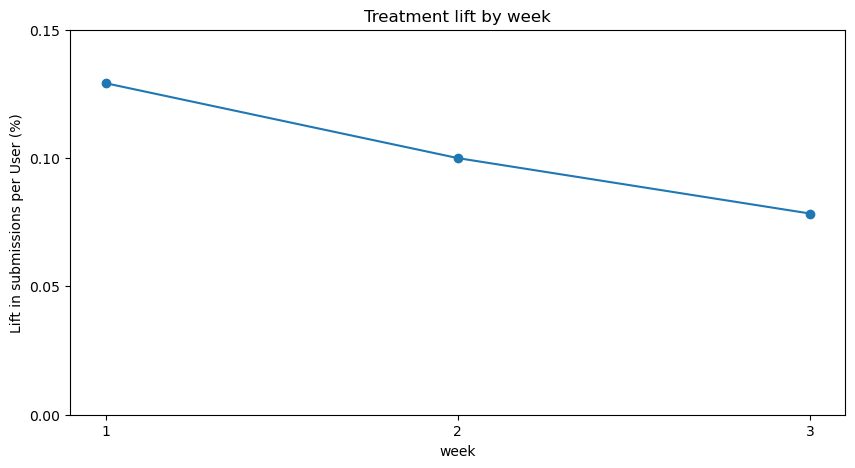

In [87]:
# TODO: join daily to clean on member_id to get variant
n_arm = clean["variant"].value_counts()
d = daily.merge(clean[["member_id", "variant"]], on = "member_id")
d["week"] = (d["date"] - pd.Timestamp("2026-10-05")).dt.days // 7 + 1 
weekly = d.groupby(["week", "variant"])["apply_submits"].sum().unstack() / n_arm
weekly["lift"] = (weekly["treatment"] - weekly["control"]) / weekly["control"]
print(weekly) 

ax = weekly["lift"].plot(marker = "o", figsize = (10,5)) 
ax.set_xticks([1,2,3])
ax.set_yticks([0.00, 0.05, 0.10, 0.15])
ax.set_title("Treatment lift by week")
ax.set_ylabel("Lift in submissions per User (%)")
plt.show()


**Checkpoint:** the lift should fall each week, from about 13% to about 8%.

**Question:** what number would you report as the expected long-run effect, and what would you do to confirm it?

What we are seeing is a **novelty effect** this is the chances that the users will react strongly to something just because they notice that it's new. Not because it's necessarily better. Once this effect wears off, they settle back to something normal. 

Even though we see a lift of *10%* in across all weeks - we see that in week 3, there is a 8% lift. Therefore, it would be important to report the 8% that was observed in week 3 and if needed, we can have a hold out group of about 5% of the members in the control to see any further long run observations. 

---
# Part E: Guardrails, the employer side

## E1. Recruiter response rate (a ratio metric)

Response rate = responses / applications. **The trap:** the unit of randomization is the member, but this metric is per application. One member's applications are correlated (a strong candidate tends to get responses on all of them), so treating applications as independent understates the SE.

Compute the difference in response rate two ways:
1. **Naive:** a two-proportion z-test that treats every application as independent.
2. **Delta method** at the member level. For each arm, with Y = responses per member and X = submits per member:
   Var(R̂) ≈ (1 / (n · X̄²)) · ( Var(Y) − 2R̂ · Cov(Y, X) + R̂² · Var(X) )

In [ ]:
def ratio_delta(df, num, den):
    # TODO: return (ratio, se) for one arm using the delta method
    y, x = df[num], df[den]
    n = len(df) 
    r = y.sum() / x.sum() 
    var = (y.var() - 2 * r * np.cov(y,x)[0,1] + r**2 * x.var()) / (n * x.mean()**2) 
    return r, np.sqrt(var) 


# TODO: response rate per arm (sum responses / sum submits) on clean
rows = {}
for v in ["control", "treatment"]:
    g = clean[clean["variant"] == v]
    r, se = ratio_delta(g, "responses", "apply_submits")
    n_apps = g["apply_submits"].sum()
    rows[v] = {"applications": n_apps, "rate": r, "se_delta": se, "se_naive": np.sqrt(r * (1-r) / n_apps)}

rr = pd.DataFrame(rows).T 

print(rr)

diff = rr.loc["treatment", "rate"] - rr.loc["control", "rate"]
se_naive = np.sqrt((rr["se_naive"] ** 2).sum()) # standard error of the difference between the two groups 
se_delta = np.sqrt((rr["se_delta"] ** 2).sum())
print(f"\nDiff = {diff:+.4f} ({diff / rr.loc['control', 'rate']:+.1%} relative)")
print(f"Naive SE = {se_naive:.4f}, z = {diff / se_naive:.1f}")
print(f"Delta SE = {se_delta:.4f}, z = {diff / se_delta:.1f}  (SE is {se_delta / se_naive:.2f}x larger)")

           applications   rate  se_delta  se_naive
control     35,881.0000 0.1871    0.0026    0.0021
treatment   39,495.0000 0.1606    0.0023    0.0018

Diff = -0.0266 (-14.2% relative)
Naive SE = 0.0028, z = -9.6
Delta SE = 0.0035, z = -7.6  (SE is 1.26x larger)


**Checkpoint:** response rate falls from about 18.7% to 16.1%. The delta-method SE should be noticeably **larger** than the naive SE.

**Questions:**
1. Is the drop significant either way?

When looking at the z-value for both, the abs value of both exceed the 1.96 benchmark for alpha set at 0.05. So, yes they are both statisically significant. 

2. Name two different reasons the response rate could fall. Can this test separate them?

* with more people applying, that could increase the number of bad applications compared to the good applications ratio. Thus, recruiters will respond less often 

* treatment will effect the passive LinkedIn members which typically get less responses anyways. 

## E2. The outcome that matters: recruiter responses per member

Seekers don't want applications, they want **responses** (interviews). Compare `responses` per member, raw and with CUPED (use `apply_submits_pre28` as the covariate again).

In [92]:
# TODO: compare_means on responses, raw and CUPED

clean, theta_r = cuped(clean, "responses", "apply_submits_pre28")
pd.DataFrame({
    "raw": compare_means(clean, "responses"),
    "cuped": compare_means(clean, "responses_cuped"),
}).T

,control,treatment,diff,lift,ci_low,ci_high,se,p_value
raw,0.1910,0.1807,-0.0103,-0.0540,-0.0209,0.0002,0.0054,0.0555
cuped,0.1921,0.1795,-0.0126,-0.0658,-0.0215,-0.0038,0.0045,0.0049


**Checkpoint:** responses per member should go **down** by a few percent. Check whether CUPED makes it significant.

**Question:** how do you reconcile "applications +10%" with this?
With CUPED, the drop in responses per member is significant (p ≈ 0.005): if One-Tap Apply had no real effect, we'd see a drop this large only about 0.5% of the time.

So the primary metric moved the "right" way while the outcome both seekers and recruiters care about got worse. Removing friction increased volume but lowered application quality. That's why we track guardrail metrics, and why I wouldn't launch on the applications lift alone.

---
# Part F: Who is driving this? (segments)

Break results down by `seeker_type` (and optionally `tenure`). For each segment, compute:
- Lift in apply submits per member
- Response rate in each arm
- Lift in responses per member

You're running several tests at once now, so apply a **Bonferroni** correction (α / number of segment tests) before calling anything significant.

In [100]:
# TODO: loop over seeker_type segments, build a summary table
# TODO: Bonferroni threshold

summary = []
for seg, g in clean.groupby("seeker_type"):
    s = compare_means(g, "apply_submits")
    r = compare_means(g, "responses")

    rate_c = g.loc[g["variant"] == "control", "responses"].sum() / g.loc[g["variant"] == "control", "apply_submits"].sum()
    rate_t = g.loc[g["variant"] == "treatment", "responses"].sum() / g.loc[g["variant"] == "treatment", "apply_submits"].sum()
    
    summary.append({
        "segment": seg,
        "members": len(g),
        "submits_lift": s["lift"],
        "submits_p": s["p_value"],
        "resp_rate_control": rate_c,
        "resp_rate_treatment": rate_t,
        "responses_lift": r["lift"],
        "responses_p": r["p_value"],
    })

seg_table = pd.DataFrame(summary).set_index("segment")
n_tests = 2 * len(seg_table)
print(f"Bonferroni threshold: {ALPHA} / {n_tests} = {ALPHA / n_tests:.4f}")
seg_table

Bonferroni threshold: 0.05 / 4 = 0.0125


,members,submits_lift,submits_p,resp_rate_control,resp_rate_treatment,responses_lift,responses_p
segment,,,,,,,
active,17594,0.0546,0.0169,0.2137,0.1883,-0.0708,0.0179
passive,52667,0.1934,0.0000,0.1134,0.0909,-0.0431,0.3524


**Checkpoint:** passive members should have the biggest lift in submits. Response rates should fall **within both segments**.

**Questions:**
1. Is the response-rate drop quality, mix shift, or both?

1. **Both.** The response rate falls *within* each segment (active 21.4% → 18.8%, passive 11.3% → 9.1%), so individual applications really are weaker (**quality**). On top of that, passive members make up a bigger share of treatment's applications, and they get responses less often to begin with (**mix shift**).

2. Which segment, if any, looks like a candidate for a targeted launch?

2. **Passive** members show the biggest volume lift (≈ +19%, clearly significant) with the weakest quality, which looks like "spray and pray" behavior. **Active** seekers get a smaller lift (≈ +5%, p ≈ 0.02) and their responses per member fall about 7% (p ≈ 0.02). Neither active result clears the Bonferroni threshold of 0.0125, so treat them as directional. No segment is a clean win, so a targeted launch isn't supported by this test. Segment cuts like these describe where the effect comes from. They aren't separate launch decisions.

---
# Part G: The deliverable

Write a launch memo for the PM and the Jobs leads. Keep it to about 150 words: decision first, then evidence, then next steps.

**Your memo:**

**Recommendation: Don't launch One-Tap Apply as-is. Iterate and retest.**

**Evidence (web + iOS, 21 days, ~70k members):**
- Apply submits per member: **+10%** (95% CI ≈ +6% to +14%). It's declining weekly (13% → 10% → 8%), so the long-run effect is likely ≤ 8%.
- Recruiter response rate: **18.7% → 16.1%** (−14%, significant with a member-level delta method).
- Responses per member, the outcome seekers and recruiters both care about: **−5% raw (p ≈ 0.06), −7% with CUPED (p ≈ 0.005)**.
- The drop shows up for both active and passive seekers, so it's application quality, not just a shift in who's applying.

**Caveats:** Android excluded due to an SRM from an exposure-logging bug. The reported +12% included that bias. Member-level randomization can't capture recruiter-side interference, so the true marketplace cost could be larger.

**Next steps:** (1) fix Android logging; (2) test a variant that keeps required screening questions and only skips optional ones; (3) for the next marketplace test, randomize at the job-posting level so recruiter-side effects are measured directly.